# 03 - RQ2: Can We Predict if a Claim Is High Severity?

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

**RQ2:** Can we predict if a claim is **high severity** (building damage in the top 20%) with the facts we know when the claim is reported?

This is a **classification** problem: the answer is yes (1) or no (0). We use the clean file from `01_EDA.ipynb`.

**Plan**
1. Prepare the data and look at the class balance
2. Choose the depth of the decision tree
3. Compare three models with cross validation
4. Final test on 2024-2025 claims the models never saw
5. Does it work in every region?
6. New data: does rainfall help?
7. Our answer

## 1. Prepare the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
SEED = 42

df = pd.read_parquet('data/claims_clean.parquet')
print('Claims:', f'{len(df):,}')

# Features: things we know when the claim is reported (no damage, no payment)
NUMBER_FEATURES = ['totalBuildingInsuranceCoverage', 'totalContentsInsuranceCoverage', 'deductible_usd', 'building_age',
                   'numberOfUnits', 'policyCount', 'crsClassCode', 'report_lag_days', 'loss_month', 'named_storm',
                   'elevatedBuildingIndicator', 'postFIRMConstructionIndicator', 'primaryResidenceIndicator', 'rentalPropertyIndicator']
CATEGORY_FEATURES = ['zone', 'foundation', 'occupancy', 'numberOfFloorsInTheInsuredBuilding', 'state_group']

top_states = df['state'].value_counts().head(10).index
df['state_group'] = df['state'].where(df['state'].isin(top_states), 'other')
X_all = pd.get_dummies(df[NUMBER_FEATURES + CATEGORY_FEATURES], columns=CATEGORY_FEATURES, dtype=int)
print('Feature columns after one-hot encoding:', X_all.shape[1])

Claims: 276,570
Feature columns after one-hot encoding: 56


In [2]:
known = df['high_severity'].notna()
X = X_all[known]
y = df.loc[known, 'high_severity'].astype(int)
years = df.loc[known, 'loss_year']
train, test = years <= 2023, years >= 2024
print(f'Claims with a known severity: {len(y):,}')
print(f'Train (2020-2023): {train.sum():,}    Test (2024-2025): {test.sum():,}')
print(f'High-severity share in train: {y[train].mean():.1%}    in test: {y[test].mean():.1%}')

Claims with a known severity: 246,237
Train (2020-2023): 142,081    Test (2024-2025): 104,156
High-severity share in train: 14.4%    in test: 27.7%


**The classes are not balanced.** Only about 1 in 5 claims is high severity. A model that always says "not severe" would have a
high accuracy but would be useless. So we do not only look at accuracy. We use:

| Score | Question it answers |
|---|---|
| Precision | Of the claims we called severe, how many really were? |
| Recall | Of the really severe claims, how many did we find? |
| F1 | One number that combines precision and recall |
| ROC-AUC | How well the model ranks severe claims above the others (0.5 = random guessing, 1 = perfect) |

We also use `class_weight='balanced'`, so the models pay more attention to the smaller class.

In [3]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
always_no = np.zeros(test.sum(), dtype=int)
print('Baseline "always predict not severe" on 2024-2025:')
print(f'   accuracy: {accuracy_score(y[test], always_no):.1%}   recall: {recall_score(y[test], always_no):.0%}   F1: {f1_score(y[test], always_no):.2f}')

Baseline "always predict not severe" on 2024-2025:
   accuracy: 72.3%   recall: 0%   F1: 0.00


## 2. Choose the depth of the decision tree

A tree that is too deep learns the training data by heart (overfitting). A tree that is too short misses patterns.
We try depths 2 to 14 with 5-fold cross validation on a 40,000-claim sample of the training years.

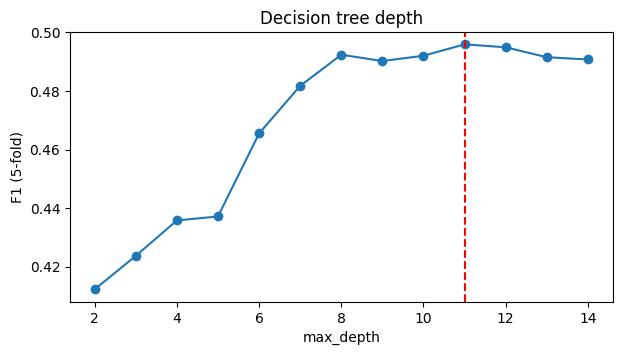

Best depth: 11   F1: 0.496


In [4]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
sample = X[train].sample(40000, random_state=SEED).index
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
depth_f1 = {}
for d in range(2, 15):
    tree = DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=SEED)
    depth_f1[d] = cross_val_score(tree, X.loc[sample], y.loc[sample], cv=cv, scoring='f1').mean()
depth_f1 = pd.Series(depth_f1)
best_depth = int(depth_f1.idxmax())
depth_f1.plot(marker='o', figsize=(7, 3.5)); plt.axvline(best_depth, color='red', ls='--')
plt.xlabel('max_depth'); plt.ylabel('F1 (5-fold)'); plt.title('Decision tree depth'); plt.show()
print('Best depth:', best_depth, '  F1:', round(depth_f1.max(), 3))

## 3. Compare three models with cross validation (training years only)

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=2000)),
    'Decision tree': DecisionTreeClassifier(max_depth=best_depth, class_weight='balanced', random_state=SEED),
    'Random forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight='balanced', n_jobs=-1, random_state=SEED),
}
cv_rows = []
for name, model in models.items():
    f1 = cross_val_score(model, X.loc[sample], y.loc[sample], cv=cv, scoring='f1')
    auc = cross_val_score(model, X.loc[sample], y.loc[sample], cv=cv, scoring='roc_auc')
    cv_rows.append({'model': name, 'F1': f1.mean(), 'F1 std': f1.std(), 'ROC-AUC': auc.mean()})
pd.DataFrame(cv_rows).set_index('model').round(3)

,F1,F1 std,ROC-AUC
model,,,
Logistic regression,0.449,0.005,0.813
Decision tree,0.496,0.006,0.816
Random forest,0.544,0.008,0.869


## 4. Final test on 2024-2025

Now we train each model on **all** training years (the random forest on a 100,000-claim sample, to save time)
and test it **once** on 2024-2025, the years of Hurricanes Helene and Milton.

In [6]:
test_rows, probs = [], {}
big_sample = X[train].sample(100000, random_state=SEED).index
for name, model in models.items():
    rows = big_sample if name == 'Random forest' else X[train].index
    model.fit(X.loc[rows], y.loc[rows])
    p = model.predict_proba(X[test])[:, 1]
    pred = (p >= 0.5).astype(int)
    probs[name] = p
    test_rows.append({'model': name, 'accuracy': accuracy_score(y[test], pred), 'precision': precision_score(y[test], pred),
                      'recall': recall_score(y[test], pred), 'F1': f1_score(y[test], pred), 'ROC-AUC': roc_auc_score(y[test], p)})
test_table = pd.DataFrame(test_rows).set_index('model')
test_table.round(3)

,accuracy,precision,recall,F1,ROC-AUC
model,,,,,
Logistic regression,0.631,0.421,0.885,0.570,0.767
Decision tree,0.660,0.440,0.824,0.573,0.779
Random forest,0.742,0.522,0.809,0.635,0.827


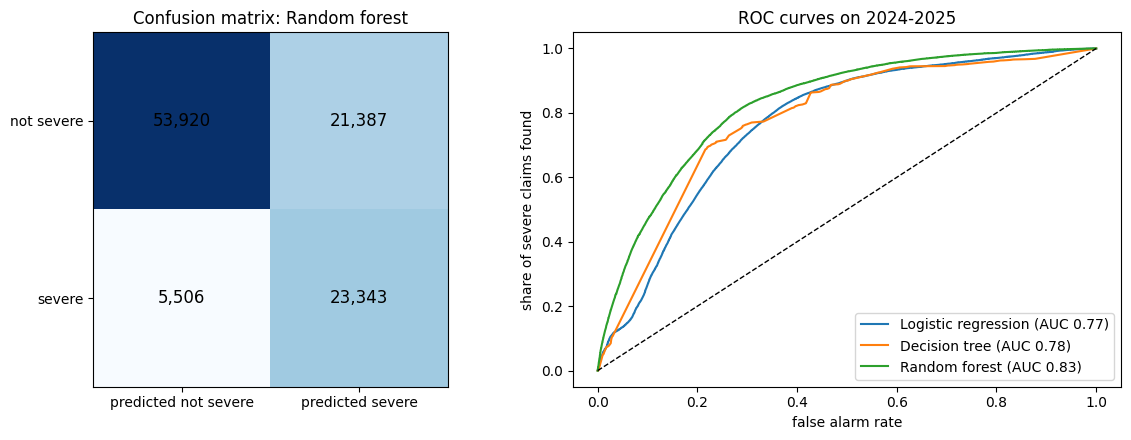

Random forest: found 23,343 of 28,849 severe claims (81%); false alarms on 28% of the other claims.


In [7]:
from sklearn.metrics import confusion_matrix, roc_curve
best = test_table['F1'].idxmax()
cm = confusion_matrix(y[test], (probs[best] >= 0.5).astype(int))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=12)
ax[0].set_xticks([0, 1], ['predicted not severe', 'predicted severe']); ax[0].set_yticks([0, 1], ['not severe', 'severe'])
ax[0].set_title(f'Confusion matrix: {best}')
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y[test], p)
    ax[1].plot(fpr, tpr, label=f"{name} (AUC {test_table.loc[name, 'ROC-AUC']:.2f})")
ax[1].plot([0, 1], [0, 1], 'k--', lw=1); ax[1].set_xlabel('false alarm rate'); ax[1].set_ylabel('share of severe claims found')
ax[1].set_title('ROC curves on 2024-2025'); ax[1].legend()
plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f'{best}: found {tp:,} of {tp + fn:,} severe claims ({tp / (tp + fn):.0%}); false alarms on {fp / (fp + tn):.0%} of the other claims.')

**What we see**
- The **random forest is the best model** on 2024-2025: F1 **0.64** and ROC-AUC **0.83**. It finds **81%** of the severe claims
  (23,343 of 28,849), but it also gives false alarms on 28% of the other claims.
- **Logistic regression** finds even more severe claims (recall 0.89), but with more false alarms (precision 0.42).
- All three models are far better than "always not severe", which finds no severe claim at all.
- The scores on the test years are close to the cross validation scores (random forest F1 0.54 in CV, 0.64 on test). Unlike RQ1,
  the model still works on new storms. Part of the higher F1 comes from the test years having more severe claims (28% vs 14%).

## 5. Does it work in every region?

We split the 2024-2025 test claims by region and score the best model in each one.

In [8]:
REGIONS = {'Florida': ['FL'], 'Gulf Coast': ['LA', 'TX', 'MS', 'AL'],
           'Mid-Atlantic & Northeast': ['NJ', 'NY', 'CT', 'RI', 'MA', 'MD', 'DE', 'DC', 'NH', 'ME', 'PA']}
state = df.loc[known, 'state']
pred = (probs[best] >= 0.5).astype(int)
region_rows = []
for region, states in list(REGIONS.items()) + [('All other states', None)]:
    in_region = state[test].isin(sum(REGIONS.values(), [])) if states is None else state[test].isin(states)
    if states is None:
        in_region = ~in_region
    yt, pt, pr = y[test][in_region.values], pred[in_region.values], probs[best][in_region.values]
    region_rows.append({'region': region, 'test claims': len(yt), 'severe share': yt.mean(), 'recall': recall_score(yt, pt),
                        'precision': precision_score(yt, pt), 'F1': f1_score(yt, pt), 'ROC-AUC': roc_auc_score(yt, pr)})
pd.DataFrame(region_rows).set_index('region').round(3)

,test claims,severe share,recall,precision,F1,ROC-AUC
region,,,,,,
Florida,73533,0.346,0.886,0.523,0.658,0.804
Gulf Coast,9693,0.095,0.147,0.359,0.209,0.746
Mid-Atlantic & Northeast,5443,0.062,0.366,0.378,0.372,0.815
All other states,15487,0.140,0.264,0.569,0.361,0.773


**What we see.** The model works well in **Florida** (F1 0.66, it finds 89% of the severe claims), but much less in the other regions:
Gulf Coast F1 0.21 and Mid-Atlantic & Northeast F1 0.37.

**Why?** Most training claims come from Florida hurricanes, so the model mostly learned what a severe *Florida* claim looks like.
Also, the high-severity line ($105,397) is the same for the whole country. In Florida 35% of the test claims cross it, but on the
Gulf Coast only 9.5% and in the Northeast 6.2%, so severe claims are rare there and harder to find.
The ROC-AUC is still 0.75-0.82 in every region, which means the model **ranks** the claims quite well everywhere.
A lower threshold than 0.5 (or a model per region) would find more severe claims outside Florida.

## 6. New data: does rainfall help?

Our features describe the building, not the flood. So we added **rainfall** for every claim from **PRISM**
(PRISM Climate Group, Oregon State University): a map of daily rain over the lower 48 states with a 4 km grid.
The script `build_rain_features.py` reads the rain at each claim's **census block group** (its population centre),
and makes 6 columns:

| Column | Meaning |
|---|---|
| `rain_lossday_mm` | rain in the 48 hours around the loss date |
| `rain_3d_mm` | rain from the day before to the day after the loss date |
| `rain_5d_mm` | rain from 3 days before to 1 day after the loss date |
| `rain_max1d_mm` | the wettest single day in those 5 days |
| `rain_nb_max1d_mm` | the wettest day in the wettest grid cell nearby (about 6 km), in case the storm cell just missed the centre |
| `rain_nb_5d_mm` | 5-day rain, taking the wettest nearby cell each day |

Rain is measured during the storm, before an adjuster visits, so it is **not leakage**: an insurer would know it a few days after the flood.
Claims in Hawaii, Alaska, Puerto Rico and the territories (0.3%) have no rain value; the random forest (scikit-learn 1.4 or newer) can work with missing values.

In [9]:
rain = pd.read_parquet('data/rain_features.parquet')
RAIN_FEATURES = [col for col in rain.columns if col.startswith('rain_') and col != 'rain_location']
rain_cols = df[['id']].merge(rain, on='id', how='left')[RAIN_FEATURES].set_index(df.index)
X_rain = pd.concat([X, rain_cols[known]], axis=1)
print('Claims with a rain value:', f'{X_rain[RAIN_FEATURES[0]].notna().mean():.1%}')

# Median 5-day rain for severe and not-severe claims
rain_cols[known].groupby(y.values).median().rename(index={0: 'not severe', 1: 'severe'}).round(0)

Claims with a rain value: 99.7%


,rain_lossday_mm,rain_3d_mm,rain_5d_mm,rain_max1d_mm,rain_nb_max1d_mm,rain_nb_5d_mm
not severe,112.0,136.0,150.0,97.0,109.0,176.0
severe,69.0,83.0,107.0,60.0,68.0,127.0


In [10]:
# Same random forest as in section 4, trained on the same 100,000 claims, with and without rain
rain_rows, rain_probs = [], {}
for name, data in [('our features', X), ('our features + rain', X_rain)]:
    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight='balanced', n_jobs=-1, random_state=SEED)
    rf.fit(data.loc[big_sample], y.loc[big_sample])
    p = rf.predict_proba(data[test])[:, 1]
    rain_probs[name] = p
    pred = (p >= 0.5).astype(int)
    rain_rows.append({'features': name, 'precision': precision_score(y[test], pred), 'recall': recall_score(y[test], pred),
                      'F1': f1_score(y[test], pred), 'ROC-AUC': roc_auc_score(y[test], p)})
rain_importance = pd.Series(rf.feature_importances_, index=X_rain.columns).sort_values(ascending=False)
pd.DataFrame(rain_rows).set_index('features').round(3)

,precision,recall,F1,ROC-AUC
features,,,,
our features,0.522,0.809,0.635,0.827
our features + rain,0.662,0.148,0.241,0.823


In [11]:
# Per region, with and without rain (ROC-AUC, so the 0.5 threshold does not matter)
rows = []
for region, states in list(REGIONS.items()) + [('All other states', None)]:
    in_region = state[test].isin(sum(REGIONS.values(), [])) if states is None else state[test].isin(states)
    if states is None:
        in_region = ~in_region
    m = in_region.values
    rows.append({'region': region, 'test claims': m.sum(),
                 'ROC-AUC our features': roc_auc_score(y[test][m], rain_probs['our features'][m]),
                 'ROC-AUC + rain': roc_auc_score(y[test][m], rain_probs['our features + rain'][m])})
print('Rain columns in the top 15 most important features:',
      [f for f in rain_importance.head(15).index if f.startswith('rain_')])
pd.DataFrame(rows).set_index('region').round(3)

Rain columns in the top 15 most important features: ['rain_nb_max1d_mm', 'rain_max1d_mm', 'rain_nb_5d_mm', 'rain_5d_mm', 'rain_3d_mm', 'rain_lossday_mm']


,test claims,ROC-AUC our features,ROC-AUC + rain
region,,,
Florida,73533,0.804,0.797
Gulf Coast,9693,0.746,0.777
Mid-Atlantic & Northeast,5443,0.815,0.803
All other states,15487,0.773,0.781


**What we see.**
- **Rain does not help here.** The ROC-AUC stays the same (0.827 without rain, 0.823 with rain).
- **With the 0.5 threshold it is even much worse:** recall falls from 0.81 to **0.15**. The model with rain finds only 15% of the severe claims.
- **Why?** Severe claims had **less** rain than the others (median 107 mm vs 150 mm in 5 days). Most severe claims are storm-surge claims on
  the Florida coast, where the sea, not the rain, did the damage. In the training years the big severe storm was Ian, which was also very
  rainy (163 mm). In the test years it was Helene, whose Florida claims got only 56 mm. The model learned "severe looks like Ian's rain",
  and this was wrong for Helene, so its probabilities dropped below 0.5 for most severe claims.
- By region, rain helps a little on the **Gulf Coast** (ROC-AUC 0.746 to 0.777) and in other states (0.773 to 0.781), and not in Florida or the Northeast.
- So for RQ2 we **keep the model without rain**. This is a good example of a feature that is important to the model
  (all 6 rain columns are in the top 15) but does not work on new storms.

## 7. Our answer to RQ2

| Model | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| Logistic regression | 0.42 | **0.89** | 0.57 | 0.77 |
| Decision tree (depth 11) | 0.44 | 0.82 | 0.57 | 0.78 |
| **Random forest** | **0.52** | 0.81 | **0.64** | **0.83** |

> **Yes, quite well.** On 2024-2025 claims that the models never saw, the random forest finds 81% of the high-severity claims
> (F1 0.64, ROC-AUC 0.83), while always saying "not severe" finds none. This is our strongest result: unlike the dollar amount (RQ1),
> severity can still be predicted for new storms. It works best in Florida (F1 0.66) and much less on the Gulf Coast (0.21) and in
> the Northeast (0.37), where severe claims are rare.

**Rainfall (section 6) did not help:** ROC-AUC stayed at 0.82 and recall at the 0.5 threshold fell to 0.15, because most severe
claims came from storm surge, not rain. Storm surge data would fit this question better.

**How it could be used:** all features are known when the claim is reported, so an insurer could flag likely large claims on the
first day and send adjusters there first.

**Limits:** 28% false alarms is a lot; the result depends on Florida; and we used one time split (a different period could give other scores).